# Лабораторная работа № 1. Исследование задачи о многоруком бандите

**Выполнил:** Лешкевич Сергей, группа 09-535

**Задача.** Есть игровой автомат с k ручками (рычагами). Ручка a приносит выигрыш rₐ с вероятностью pₐ, иначе 0.
Значит, в среднем она даёт q\*(a) = pₐ · rₐ — это её ценность, но агент её не знает. На каждом шаге агент дёргает одну ручку
и получает награду. Цель — набрать как можно больше награды: быстро найти лучшую ручку и не потратить слишком много шагов на проверку плохих.

**План исследования.**
1. Сделать среду (по образцу учебного блокнота) и четыре стратегии выбора действий:
   жадную, ε-жадную, UCB (верхняя доверительная граница) и градиентную (стохастический градиентный подъём + softmax).
2. Сравнить стратегии на автоматах с разным числом ручек: k = 3, 5, 10, 20.
3. Посмотреть, как на результат влияют параметры каждой стратегии: ε, Q₀, c, α, базовая линия.
4. Сравнивать по графикам **средней награды** (среднее по 2000 независимых запусков по 1000 шагов)
   и по доле шагов, где выбрана лучшая ручка.

**Как устроен эксперимент.** В каждом запуске генерируется свой случайный автомат: pₐ ~ U(0, 1), rₐ ∈ {1, …, 5}.
Все стратегии играют на одних и тех же наборах автоматов (одинаковый seed), поэтому разница между кривыми — это заслуга
стратегии, а не везение со средой. Все 2000 запусков считаются одновременно через массивы NumPy, поэтому весь блокнот
выполняется примерно за минуту.

In [1]:
# numpy - вся математика, matplotlib - графики
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker  # нужен, чтобы подписать ось x дробями 1/16, 1/4 и т.д.
from functools import partial  # partial(f, x=1) - это та же f, но с уже подставленным x=1

# Общий вид всех графиков, чтобы не настраивать каждый по отдельности:
# светлая сетка, без верхней и правой рамки, линии потолще, легенда без рамки
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.grid': True,
    'grid.color': '#e4e3df',
    'grid.linewidth': 0.8,
    'axes.edgecolor': '#b5b4ad',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'lines.linewidth': 1.6,
    'legend.frameon': False,
    'font.size': 9,
})

## 1. Среда

`BanditEnv` — тот же автомат, что в учебном блокноте (`payout_list`, `reward_list`, метод `step`),
только сразу на R автоматов: так можно усреднять по тысячам запусков без цикла по ним.
`GaussianBanditEnv` — классический стенд из книги Саттона и Барто, на нём делается контрольная проверка в конце.

In [2]:
class BanditEnv:
    # Игровой автомат из методички. У ручки a есть шанс выигрыша payout[a]
    # и размер выигрыша reward[a]: дёрнул ручку - получил либо reward[a], либо 0.
    #
    # Отличие от методички одно: тут сразу R автоматов, по одному на каждый запуск.
    # Поэтому payout и reward - это таблицы R x k (строка - автомат, столбец - ручка).
    # Так 2000 партий играются одновременно, и не нужен цикл по партиям.

    def __init__(self, payout, reward, rng):
        self.payout = np.asarray(payout, dtype=float)  # шансы выигрыша, таблица R x k
        self.reward = np.asarray(reward, dtype=float)  # размеры выигрыша, тоже R x k
        self.rng = rng  # свой генератор случайных чисел, чтобы результат повторялся
        self.n_runs, self.n_arms = self.payout.shape  # R автоматов, k ручек

        # Сколько ручка приносит в среднем: шанс * выигрыш. Это её "ценность" q*.
        # Агент её не видит! Она нужна только нам, чтобы понять, насколько хорошо он играет.
        self.q_true = self.payout * self.reward
        self.best_action = self.q_true.argmax(axis=1)  # номер лучшей ручки в каждом автомате
        self.best_value = self.q_true.max(axis=1)  # сколько в среднем даёт эта лучшая ручка
        self._idx = np.arange(self.n_runs)  # 0, 1, ..., R-1 - номера автоматов, для индексации

    @classmethod
    def fixed(cls, payout_list, reward_list, n_runs, rng):
        # Один и тот же автомат во всех запусках, как в методичке.
        # np.tile просто копирует строчку n_runs раз, получается таблица R x k.
        payout = np.tile(payout_list, (n_runs, 1))
        reward = np.tile(reward_list, (n_runs, 1))
        return cls(payout, reward, rng)

    @classmethod
    def random(cls, n_arms, n_runs, rng):
        # В каждом запуске свой случайный автомат. Тогда выводы не зависят
        # от одного удачного или неудачного набора ручек.
        payout = rng.uniform(0.0, 1.0, size=(n_runs, n_arms))  # шанс выигрыша от 0 до 1
        reward = rng.integers(1, 6, size=(n_runs, n_arms))  # выигрыш от 1 до 5 (6 не входит)
        return cls(payout, reward, rng)

    def step(self, action):
        # action - массив из R чисел: какую ручку дёрнули в каждом из R автоматов.
        p = self.payout[self._idx, action]  # шанс выигрыша выбранной ручки в каждом автомате
        r = self.reward[self._idx, action]  # и сколько она платит при выигрыше
        # Кидаем R случайных чисел от 0 до 1. Где число меньше шанса - выиграли r, иначе 0.
        return np.where(self.rng.random(self.n_runs) < p, r, 0.0)


class GaussianBanditEnv:
    # Стенд из учебника Саттона и Барто, нужен только для проверки в конце.
    # Ценность ручки q* берётся из нормального распределения N(0, 1),
    # а награда за ручку - это её q* плюс шум из N(0, 1).

    def __init__(self, n_arms, n_runs, rng):
        self.rng = rng
        self.n_runs, self.n_arms = n_runs, n_arms
        self.q_true = rng.normal(0.0, 1.0, size=(n_runs, n_arms))  # ценности ручек, R x k
        self.best_action = self.q_true.argmax(axis=1)  # лучшая ручка в каждом автомате
        self.best_value = self.q_true.max(axis=1)  # её ценность
        self._idx = np.arange(n_runs)

    def step(self, action):
        # награда = ценность выбранной ручки + случайный шум
        return self.rng.normal(self.q_true[self._idx, action], 1.0)

## 2. Стратегии выбора действий

* **Случайная** стратегия из учебного блокнота: каждый раз дёргает ручку наугад. Нужна как нижняя планка.
* **Жадная** (ε = 0): всегда дёргает ручку, у которой сейчас наибольшая оценка Q(a). Оценка Q(a) — это средняя награда,
  которую эта ручка уже принесла. Пересчитывается после каждого шага без хранения всей истории:

$$Q \leftarrow Q + \dfrac{1}{N}\,(R - Q)$$

  Вариант с **оптимистичными начальными оценками** (Q₀ > 0): в начале все оценки завышены, поэтому агент по очереди
  перепробует все ручки, пока их оценки не опустятся до реальных.
* **ε-жадная**: с вероятностью ε дёргает случайную ручку (исследует), в остальных случаях — жадный выбор.
* **UCB** (верхняя доверительная граница): к оценке ручки добавляется бонус за неуверенность. Чем реже ручку пробовали,
  тем больше бонус. Ручки, которые ещё ни разу не пробовали, выбираются в первую очередь.

$$A_t = \arg\max_a \left[ Q_t(a) + c\,\sqrt{\dfrac{\ln t}{N_t(a)}} \right]$$

* **Градиентная**: агент хранит не оценки, а «предпочтения» H(a). Ручку выбирает случайно, с вероятностями softmax.
  После каждого шага сдвигает предпочтения в сторону, где награда выше средней (стохастический градиентный подъём):

$$\pi_t(a) = \dfrac{e^{H_t(a)}}{\sum_b e^{H_t(b)}}$$

$$H(A_t) \leftarrow H(A_t) + \alpha\,(R_t - \bar{R}_t)\,(1 - \pi_t(A_t)), \qquad H(a) \leftarrow H(a) - \alpha\,(R_t - \bar{R}_t)\,\pi_t(a),\ a \neq A_t$$

  R̄ — средняя полученная награда (базовая линия). Вариант без неё (R̄ = 0) тоже исследуется.

In [3]:
def argmax_random(values, rng):
    # Обычный argmax при равенстве всегда берёт первую ручку. Нам это не подходит:
    # в начале все оценки равны, и агент всегда дёргал бы ручку 0.
    # Поэтому ничьи разбиваем случайно.
    is_max = values == values.max(axis=1, keepdims=True)  # True там, где значение максимальное
    # Умножаем на случайные числа: у не-максимумов будет 0, у максимумов - случайное число.
    # Берём наибольшее - получается случайный из максимумов.
    return np.argmax(is_max * rng.random(values.shape), axis=1)


class RandomAgent:
    # Стратегия из методички: каждый раз случайная ручка. Ничему не учится.

    def __init__(self, n_runs, n_arms, rng):
        self.n_runs, self.n_arms, self.rng = n_runs, n_arms, rng

    def select(self):
        return self.rng.integers(0, self.n_arms, size=self.n_runs)  # по случайной ручке на автомат

    def update(self, action, reward):
        pass  # учиться нечему


class EpsilonGreedyAgent:
    # Жадная и ε-жадная стратегия в одном классе.
    # epsilon=0 - чисто жадная. q0 - с какой оценки стартуют ручки (q0 > 0 - "оптимизм").

    def __init__(self, n_runs, n_arms, rng, epsilon=0.1, q0=0.0):
        self.n_runs, self.n_arms, self.rng = n_runs, n_arms, rng
        self.epsilon = epsilon  # как часто дёргаем случайную ручку
        self.Q = np.full((n_runs, n_arms), float(q0))  # оценки ручек: сначала у всех q0
        self.N = np.zeros((n_runs, n_arms))  # сколько раз дёргали каждую ручку
        self._idx = np.arange(n_runs)  # номера автоматов 0..R-1

    def select(self):
        action = argmax_random(self.Q, self.rng)  # жадный выбор: ручка с наибольшей оценкой
        if self.epsilon > 0:
            # в каких автоматах на этом шаге исследуем (выпало число меньше ε)
            explore = self.rng.random(self.n_runs) < self.epsilon
            random_action = self.rng.integers(0, self.n_arms, size=self.n_runs)  # случайные ручки
            action = np.where(explore, random_action, action)  # где исследуем - случайная ручка
        return action

    def update(self, action, reward):
        i = self._idx
        self.N[i, action] += 1  # ещё раз дёрнули эту ручку
        # Пересчитываем среднее, не храня всю историю: сдвигаем оценку к новой награде
        # на 1/N от разницы. Это то же самое, что сумма наград / число попыток.
        self.Q[i, action] += (reward - self.Q[i, action]) / self.N[i, action]


class UCBAgent:
    # Выбор по верхней доверительной границе: оценка + бонус за неуверенность.
    # c - насколько сильно ценим неуверенность (больше c - больше исследуем).

    def __init__(self, n_runs, n_arms, rng, c=2.0):
        self.n_runs, self.n_arms, self.rng = n_runs, n_arms, rng
        self.c = c
        self.Q = np.zeros((n_runs, n_arms))  # оценки ручек, как у жадной
        self.N = np.zeros((n_runs, n_arms))  # сколько раз дёргали каждую ручку
        self.t = 0  # номер шага
        self._idx = np.arange(n_runs)

    def select(self):
        self.t += 1
        # Бонус большой у ручек, которые дёргали мало (N маленькое).
        # ln t медленно растёт, поэтому про забытые ручки агент со временем вспоминает.
        # errstate глушит предупреждение numpy о делении на ноль у ещё не тронутых ручек.
        with np.errstate(divide="ignore", invalid="ignore"):
            bonus = self.c * np.sqrt(np.log(self.t) / self.N)
        # Ручки, которые ни разу не дёргали, получают бесконечность - их пробуем первыми
        ucb = np.where(self.N == 0, np.inf, self.Q + bonus)
        return argmax_random(ucb, self.rng)

    def update(self, action, reward):
        # оценку обновляем так же, как у жадной: среднее наград ручки
        i = self._idx
        self.N[i, action] += 1
        self.Q[i, action] += (reward - self.Q[i, action]) / self.N[i, action]


class GradientAgent:
    # Градиентный бандит. Вместо оценок у агента "предпочтения" H(a) для каждой ручки.
    # Через softmax они превращаются в вероятности, и ручка выбирается случайно по ним.
    # alpha - шаг обучения, baseline - сравнивать ли награду со средней.

    def __init__(self, n_runs, n_arms, rng, alpha=0.1, baseline=True):
        self.n_runs, self.n_arms, self.rng = n_runs, n_arms, rng
        self.alpha = alpha
        self.baseline = baseline
        self.H = np.zeros((n_runs, n_arms))  # предпочтения: сначала все равны, т.е. выбор наугад
        self.avg_reward = np.zeros(n_runs)  # средняя награда за всё время - базовая линия
        self.t = 0  # номер шага
        self._idx = np.arange(n_runs)

    def policy(self):
        # softmax: вероятность ручки = e^H(a) / сумма e^H по всем ручкам.
        # Перед экспонентой вычитаем максимум. Ответ от этого не меняется,
        # зато e^H не улетает в бесконечность при больших H.
        z = self.H - self.H.max(axis=1, keepdims=True)
        e = np.exp(z)
        return e / e.sum(axis=1, keepdims=True)

    def select(self):
        self.pi = self.policy()  # вероятности ручек, запоминаем - нужны в update
        # Выбор ручки по вероятностям. Режем отрезок [0, 1] на куски длиной pi(a)
        # и смотрим, в какой кусок попало случайное число u.
        u = self.rng.random((self.n_runs, 1))
        action = (self.pi.cumsum(axis=1) < u).sum(axis=1)  # сколько границ левее u = номер куска
        return np.minimum(action, self.n_arms - 1)  # страховка от погрешности округления

    def update(self, action, reward):
        self.t += 1
        if self.baseline:
            # обновляем среднюю награду так же, как Q у жадной
            self.avg_reward += (reward - self.avg_reward) / self.t
        one_hot = np.zeros_like(self.H)
        one_hot[self._idx, action] = 1.0  # единица у выбранной ручки, нули у остальных
        # Насколько награда лучше средней. Без базовой линии avg_reward остаётся нулём,
        # и тогда это просто сама награда.
        advantage = (reward - self.avg_reward)[:, None]
        # Шаг градиентного подъёма. Если награда выше средней, выбранной ручке
        # предпочтение растёт, остальным падает. Если ниже - наоборот.
        self.H += self.alpha * advantage * (one_hot - self.pi)

## 3. Прогон эксперимента

Функция `run` — это тот же цикл, что в учебном блокноте: выбрать действие → получить награду → обновить знания.
Только делается сразу для 2000 автоматов, а после каждого шага запоминается средняя по ним награда.

In [4]:
def run(make_env, make_agent, n_steps=1000, n_runs=2000, seed=0):
    # Прогоняет стратегию на n_runs автоматах по n_steps шагов и усредняет результат.
    # make_env(n_runs, rng) создаёт среду, make_agent(n_runs, n_arms, rng) - агента.
    # Среда всегда создаётся с одним и тем же seed, поэтому все стратегии
    # играют на одинаковых автоматах и сравнение честное.
    env = make_env(n_runs, np.random.default_rng(seed))
    agent = make_agent(n_runs, env.n_arms, np.random.default_rng(seed + 1))

    rewards = np.empty(n_steps)  # средняя по автоматам награда на каждом шаге
    optimal = np.empty(n_steps)  # доля автоматов, где на этом шаге дёрнули лучшую ручку
    for t in range(n_steps):
        action = agent.select()  # агент выбирает ручку (в каждом из R автоматов)
        reward = env.step(action)  # автоматы выдают награды
        agent.update(action, reward)  # агент учится на том, что получил
        rewards[t] = reward.mean()
        optimal[t] = (action == env.best_action).mean()

    return {
        'reward': rewards,  # средняя награда на шаге t
        # средняя награда за все шаги с 1 по t (как на графике из методички)
        'cum_reward': rewards.cumsum() / np.arange(1, n_steps + 1),
        'optimal': optimal,  # доля выбора лучшей ручки на шаге t
        'best_value': env.best_value.mean(),  # потолок: сколько в среднем даёт лучшая ручка
    }

### Вспомогательные функции для графиков

У каждой стратегии свой цвет, одинаковый на всех графиках. Когда перебирается параметр одной стратегии,
цвета идут в фиксированном порядке по возрастанию параметра.

In [5]:
N_STEPS, N_RUNS = 1000, 2000  # 1000 шагов в каждом запуске, 2000 запусков
ARMS = [3, 5, 10, 20]  # сколько ручек у автомата в разных экспериментах

# цвет каждой стратегии - одинаковый на всех графиках
COLORS = {
    'Случайная': '#a3a29c',
    'Жадная': '#2a78d6',
    'ε-жадная': '#eb6834',
    'UCB': '#1baf7a',
    'Градиентная': '#c98500',
    'Жадная, оптимистичная': '#e87ba4',
    'Градиентная без baseline': '#6250d6',
}
# цвета по порядку - для графиков, где перебирается один параметр
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']


def random_env(k):
    # "фабрика" сред: возвращает функцию, которая создаёт случайные автоматы с k ручками
    return lambda n, rng: BanditEnv.random(k, n, rng)


def smooth(y, w=20):
    # Скользящее среднее по w шагам: каждая точка - среднее её и w-1 предыдущих.
    # Нужно только чтобы кривые на графиках меньше дрожали.
    c = np.cumsum(np.insert(y, 0, 0.0))  # накопленные суммы, с нулём в начале
    head = c[1:w] / np.arange(1, w)  # первые w-1 точек: среднее по тому, что есть
    return np.concatenate([head, (c[w:] - c[:-w]) / w])  # дальше - среднее ровно по w точкам


def plot_curves(ax, results, key, colors, best=None, title=None):
    # Рисует по линии на каждую стратегию из results.
    # key - что рисуем: 'reward' (награда на шаге), 'cum_reward' (накопленная средняя)
    # или 'optimal' (% выбора лучшей ручки).
    # colors - словарь {название: цвет} или просто список цветов по порядку.
    for i, (label, res) in enumerate(results.items()):
        color = colors[label] if isinstance(colors, dict) else colors[i]
        y = res[key]
        if key == 'optimal':
            y = y * 100  # доли переводим в проценты
        if key != 'cum_reward':
            y = smooth(y)  # шумные кривые сглаживаем; накопленная и так гладкая
        ax.plot(np.arange(1, len(y) + 1), y, color=color, label=label)  # шаги нумеруем с 1
    if best is not None and key != 'optimal':
        # пунктир - сколько в среднем даёт лучшая ручка; выше в среднем не прыгнешь
        ax.axhline(best, color='#52514e', linestyle='--', linewidth=1)
        ax.annotate('лучший рычаг', (len(y), best), xytext=(-4, 3), textcoords='offset points',
                    ha='right', va='bottom', color='#52514e', fontsize=8)
    ax.set_xlabel('Шаг')
    ax.set_ylabel({'reward': 'Средняя награда',
                   'cum_reward': 'Средняя накопленная награда',
                   'optimal': 'Оптимальный рычаг, %'}[key])
    if title:
        ax.set_title(title, loc='left', fontsize=10)


def top_legend(fig, ax, ncol, top=0.9):
    # Одна общая легенда над всеми графиками, чтобы не закрывать линии
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower left', ncol=ncol, bbox_to_anchor=(0.01, top))
    fig.tight_layout(rect=(0, 0, 1, top))  # оставляем место сверху под легенду

## 4. Автомат из учебного блокнота

Сначала автомат из методички: три ручки, `payout = [0.1, 0.15, 0.3]`, `reward = [4, 3, 1]`.
Ценности ручек q\* = [0.40, 0.45, 0.30]: лучшая — вторая (номер 1), но она лишь чуть лучше первой,
поэтому различить их трудно. Слева — график как в методичке (оценки ручек при случайной стратегии, один запуск),
справа — средняя накопленная награда разных стратегий (ось времени логарифмическая, как в методичке).

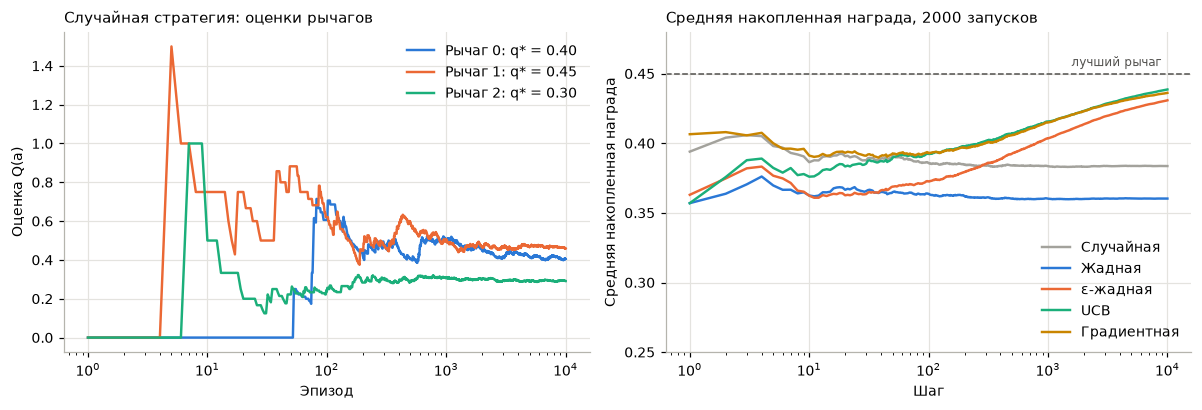

Случайная     награда за 10000 шагов: 0.384   оптимальный рычаг на последних 1000 шагах: 33.3 %
Жадная        награда за 10000 шагов: 0.360   оптимальный рычаг на последних 1000 шагах: 28.4 %
ε-жадная      награда за 10000 шагов: 0.431   оптимальный рычаг на последних 1000 шагах: 82.7 %
UCB           награда за 10000 шагов: 0.439   оптимальный рычаг на последних 1000 шагах: 91.9 %
Градиентная   награда за 10000 шагов: 0.436   оптимальный рычаг на последних 1000 шагах: 83.2 %


In [6]:
payout, reward = [0.1, 0.15, 0.3], [4, 3, 1]  # автомат из методички
fixed_env = lambda n, rng: BanditEnv.fixed(payout, reward, n, rng)
N_LONG = 10000  # тут играем дольше, 10 000 шагов, как в методичке

# Повторяем опыт из методички: один запуск, ручки дёргаем наугад и смотрим,
# как меняются оценки Q(a). ε = 1 - это ровно случайная стратегия, но с подсчётом Q.
rng = np.random.default_rng(42)
env = BanditEnv.fixed(payout, reward, 1, rng)
agent = EpsilonGreedyAgent(1, 3, rng, epsilon=1.0)
history = np.empty((N_LONG, 3))  # оценки трёх ручек на каждом шаге
for t in range(N_LONG):
    a = agent.select()
    agent.update(a, env.step(a))
    history[t] = agent.Q[0]

# Стратегии с "типичными" параметрами. partial подставляет параметры заранее,
# и run потом создаёт агента как make_agent(n_runs, n_arms, rng).
strategies = {
    'Случайная': RandomAgent,
    'Жадная': partial(EpsilonGreedyAgent, epsilon=0.0),
    'ε-жадная': partial(EpsilonGreedyAgent, epsilon=0.1),
    'UCB': partial(UCBAgent, c=1.0),
    'Градиентная': partial(GradientAgent, alpha=0.1),
}
fixed_results = {name: run(fixed_env, make, N_LONG, N_RUNS) for name, make in strategies.items()}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))  # два графика рядом
# левый: как оценки трёх ручек меняются со временем
for a in range(3):
    ax1.plot(np.arange(1, N_LONG + 1), history[:, a], color=SERIES[a],
             label=f'Рычаг {a}: q* = {payout[a] * reward[a]:.2f}')
ax1.set_xscale('log')  # логарифмическая ось: видно и первые шаги, и тысячные
ax1.set_xlabel('Эпизод')
ax1.set_ylabel('Оценка Q(a)')
ax1.set_title('Случайная стратегия: оценки рычагов', loc='left', fontsize=10)
ax1.legend()
# правый: средняя накопленная награда каждой стратегии
plot_curves(ax2, fixed_results, 'cum_reward', COLORS, best=0.45,
            title='Средняя накопленная награда, 2000 запусков')
ax2.set_xscale('log')
ax2.set_ylim(0.25, 0.48)
ax2.legend(loc='lower right')
plt.tight_layout()
plt.show()

for name, res in fixed_results.items():
    print(f"{name:12s}  награда за {N_LONG} шагов: {res['cum_reward'][-1]:.3f}   "
          f"оптимальный рычаг на последних 1000 шагах: {100 * res['optimal'][-1000:].mean():.1f} %")

**Наблюдения.**

* Задача трудная: лучшая ручка (q\* = 0.45) лишь на 0.05 лучше соседней (0.40), а награды сильно скачут.
  На левом графике видно, что оценки ручек при случайной стратегии сильно прыгают первые сотни шагов,
  и правильный порядок ручек устанавливается только к ~1000 шагов.
* **Жадная стратегия здесь хуже случайной** (0.360 против 0.384). Чаще всего первой выигрыш приносит ручка 2:
  у неё самый большой шанс выплаты (0.3), но самая маленькая ценность. После этого её оценка больше нуля,
  у остальных ручек оценка ноль, и агент к ним больше не возвращается. Лучшую ручку жадная стратегия
  выбирает только в 28 % запусков.
* ε-жадная, UCB и градиентная стратегии примерно до 100-го шага ведут себя как случайная (идёт исследование),
  затем средняя награда растёт к 0.45. За 10 000 шагов лучший результат у **UCB** (0.439; на последних 1000 шагах
  лучшая ручка выбирается в 92 % случаев). Градиентная (0.436, 83 %) и ε-жадная (0.431, 83 %) немного уступают:
  ε-жадная всегда тратит 10 % шагов на случайные действия.

## 5. Сравнение стратегий при разном числе рычагов

Параметры стратегий типичные: ε-жадная ε = 0.1, UCB c = 1, градиентная α = 0.1 с базовой линией.
Пунктир — средняя ценность лучшей ручки (потолок). Кривые средней награды на шаге сглажены скользящим средним по 20 шагам.

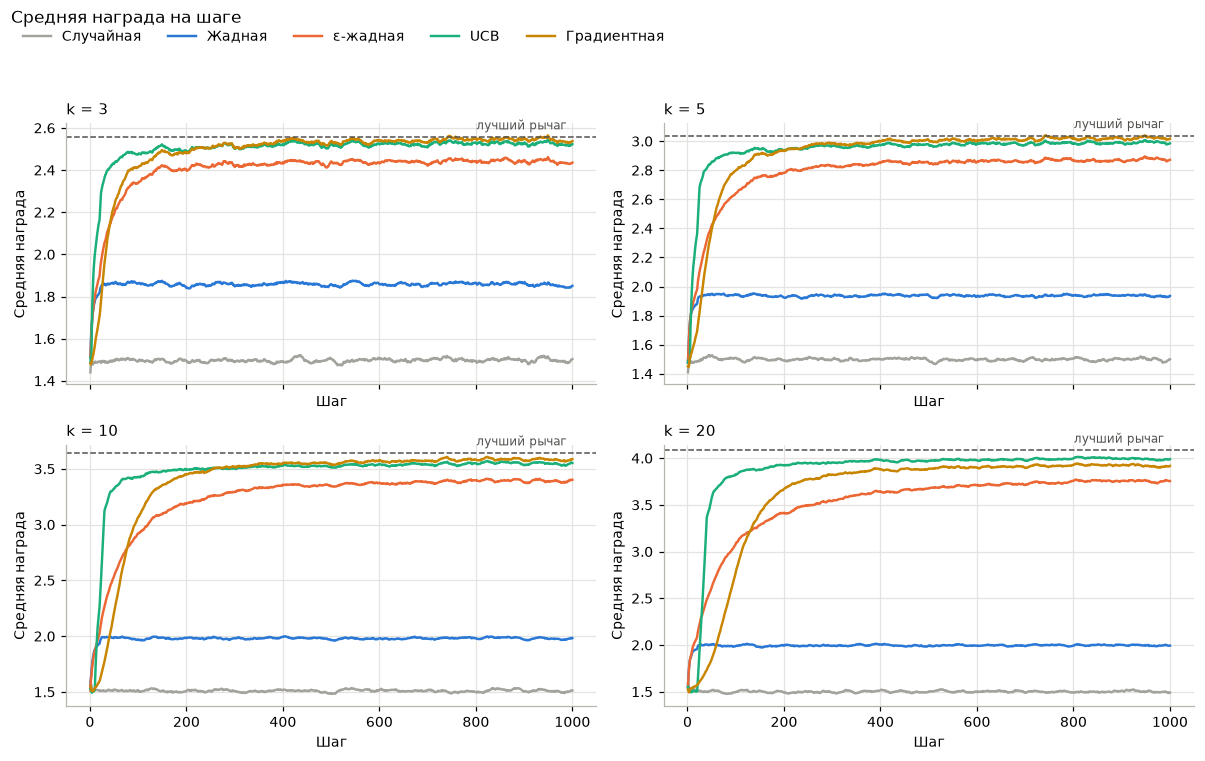

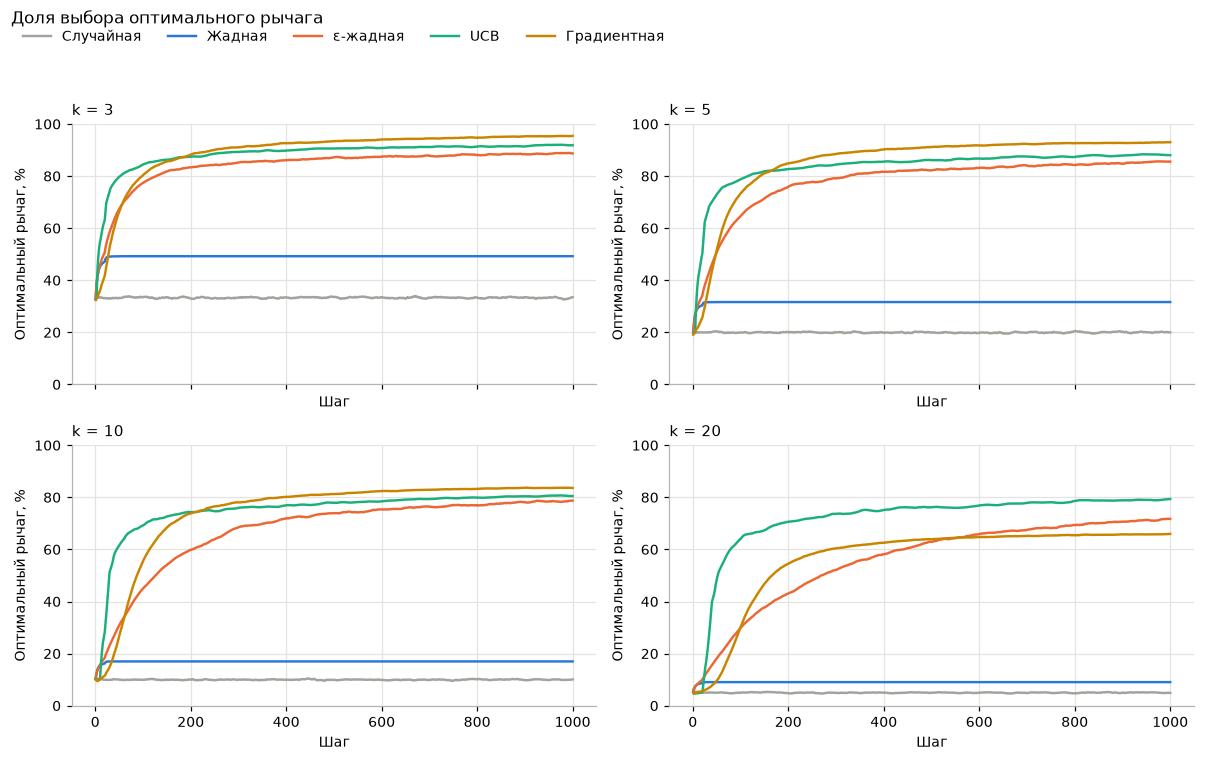

In [7]:
# Для каждого k прогоняем все стратегии. Получается словарь: comparison[k][название] = результат run
comparison = {k: {name: run(random_env(k), make, N_STEPS, N_RUNS) for name, make in strategies.items()}
              for k in ARMS}

# Две картинки по 4 графика: сначала средняя награда, потом % выбора лучшей ручки
for key in ['reward', 'optimal']:
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)  # сетка 2 x 2, общая ось x
    for ax, k in zip(axes.flat, ARMS):  # по графику на каждое k
        best = comparison[k]['Жадная']['best_value']  # потолок одинаков для всех стратегий
        plot_curves(ax, comparison[k], key, COLORS, best=best, title=f'k = {k}')
        if key == 'optimal':
            ax.set_ylim(0, 100)
    fig.suptitle('Средняя награда на шаге' if key == 'reward' else 'Доля выбора оптимального рычага',
                 x=0.01, ha='left')
    top_legend(fig, axes[0, 0], ncol=5, top=0.92)
    plt.show()

**Наблюдения.**

* **Случайная** стратегия при любом k даёт ≈ 1.5 (в среднем шанс 0.5 × выигрыш 3) и выбирает лучшую ручку с частотой 1/k.
* **Жадная** (Q₀ = 0) застревает на уровне 1.86–2.0 при любом k: она «прилипает» к первой ручке,
  которая принесла выигрыш. Лучшую ручку она выбирает в 49 / 32 / 17 / 9 % запусков — ненамного чаще случайной.
  Потолок с ростом k растёт (2.56 → 4.09), а жадная стратегия стоит на месте, поэтому её отставание растёт.
* **UCB** быстрее всех выходит на плато (50–100 шагов) при любом k. Каждая ручка сначала пробуется один раз,
  а дальше агент проверяет те ручки, про которые меньше всего знает. При k = 20 это явный лидер:
  3.90 в среднем за 1000 шагов при потолке 4.09.
* **Градиентная** стратегия стартует медленнее: вначале все предпочтения равны, и проходит 100–200 шагов,
  пока вероятность не сосредоточится на хорошей ручке. Зато к концу при k = 3, 5, 10 она чаще всех выбирает
  лучшую ручку (95 / 93 / 84 %), а по награде идёт наравне с UCB. При k = 20 с α = 0.1 она отстаёт (66 %):
  на 20 ручках учиться дольше (в разделе 7 видно, что там лучше α = 0.25).
* **ε-жадная** (ε = 0.1) учится стабильно, но всегда на 0.1–0.35 ниже UCB и градиентной.
  В пределе она теряет примерно ε × (q\*лучшей − средняя q\*) из-за обязательных случайных ходов;
  при k = 10 это 0.1 × (3.64 − 1.51) ≈ 0.21.
* **С ростом числа ручек** все методы учатся медленнее (кривые поднимаются позже) и реже выбирают лучшую ручку
  (UCB 92 → 79 %, ε-жадная 89 → 71 %, градиентная 95 → 66 %). А сама награда растёт: среди большего числа ручек
  лучшая в среднем лучше.

## 6. Влияние параметров (k = 10)

Для каждой стратегии перебирается её параметр при k = 10:
* жадная: начальная оценка Q₀ (0 — обычная, больше — оптимистичная);
* ε-жадная: вероятность исследования ε;
* UCB: коэффициент исследования c;
* градиентная: шаг α, с базовой линией и без неё.

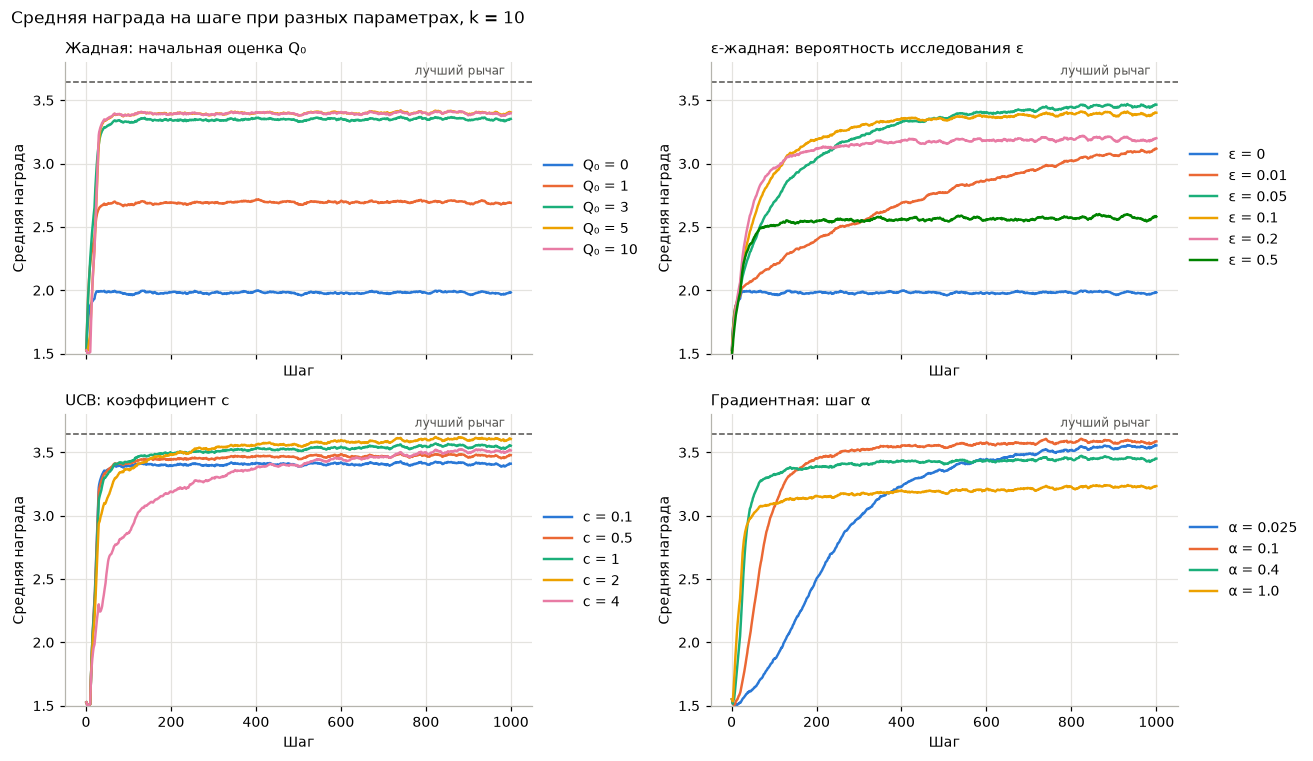

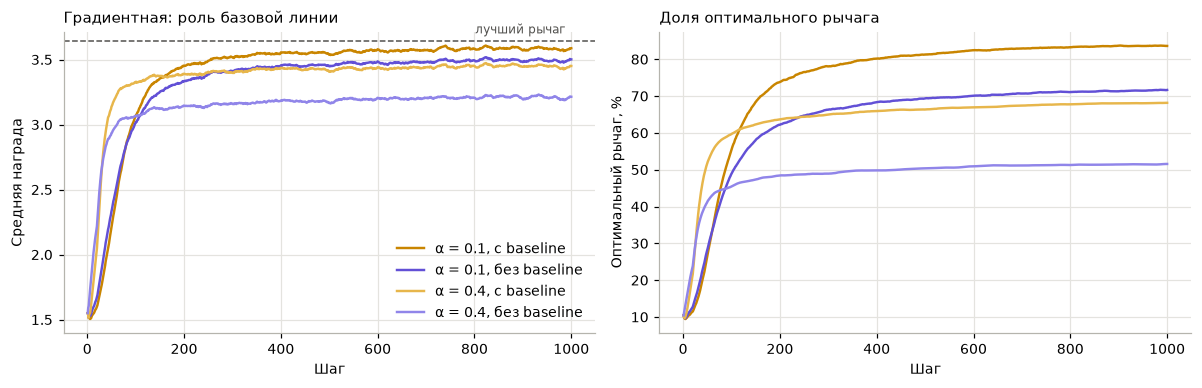

                                           награда (1000 шагов)  оптимальный рычаг (посл. 100), %
Жадная: начальная оценка Q₀
    Q₀ = 0                                    1.980                 17.0
    Q₀ = 1                                    2.688                 30.8
    Q₀ = 3                                    3.333                 60.5
    Q₀ = 5                                    3.375                 67.1
    Q₀ = 10                                   3.374                 66.6
ε-жадная: вероятность исследования ε
    ε = 0                                     1.980                 17.0
    ε = 0.01                                  2.717                 51.5
    ε = 0.05                                  3.226                 77.6
    ε = 0.1                                   3.253                 78.5
    ε = 0.2                                   3.116                 72.8
    ε = 0.5                                   2.542                 51.0
UCB: коэффициент c
    c = 0.1    

In [8]:
K = 10
# Для каждой стратегии - набор вариантов с разными значениями параметра.
# Ключ внутри - подпись в легенде, значение - как создать такого агента.
sweeps = {
    'Жадная: начальная оценка Q₀': {
        f'Q₀ = {q0}': partial(EpsilonGreedyAgent, epsilon=0.0, q0=q0) for q0 in [0, 1, 3, 5, 10]},
    'ε-жадная: вероятность исследования ε': {
        f'ε = {eps}': partial(EpsilonGreedyAgent, epsilon=eps)
        for eps in [0, 0.01, 0.05, 0.1, 0.2, 0.5]},
    'UCB: коэффициент c': {
        f'c = {c}': partial(UCBAgent, c=c) for c in [0.1, 0.5, 1, 2, 4]},
    'Градиентная: шаг α': {
        f'α = {a}': partial(GradientAgent, alpha=a) for a in [0.025, 0.1, 0.4, 1.0]},
}
# прогоняем все варианты
sweep_results = {
    title: {label: run(random_env(K), make, N_STEPS, N_RUNS) for label, make in group.items()}
    for title, group in sweeps.items()
}
# отдельно - градиентная с базовой линией и без неё, при двух разных α
baseline_results = {
    f'α = {a}{suffix}': run(random_env(K), partial(GradientAgent, alpha=a, baseline=b), N_STEPS, N_RUNS)
    for a in [0.1, 0.4] for b, suffix in [(True, ', с baseline'), (False, ', без baseline')]
}
best10 = comparison[K]['Жадная']['best_value']  # потолок для k = 10

# Картинка 1: по графику на каждую стратегию, линии - разные значения параметра
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, (title, res) in zip(axes.flat, sweep_results.items()):
    plot_curves(ax, res, 'reward', SERIES, best=best10, title=title)
    ax.set_ylim(1.5, 3.8)
    ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))  # легенда справа от графика
fig.suptitle('Средняя награда на шаге при разных параметрах, k = 10', x=0.01, ha='left')
plt.tight_layout()
plt.show()

# Картинка 2: градиентная с базовой линией и без - награда и % лучшей ручки
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, key in zip(axes, ['reward', 'optimal']):
    title = 'Градиентная: роль базовой линии' if key == 'reward' else 'Доля оптимального рычага'
    plot_curves(ax, baseline_results, key, ['#c98500', '#6250d6', '#e7b64b', '#9085e9'],
                best=best10 if key == 'reward' else None, title=title)
axes[0].legend(loc='lower right')
plt.tight_layout()
plt.show()

# Табличка с цифрами: средняя награда за 1000 шагов и % лучшей ручки на последних 100 шагах
print(f"{'':42s} награда (1000 шагов)  оптимальный рычаг (посл. 100), %")
for title, res in list(sweep_results.items()) + [('Градиентная: базовая линия', baseline_results)]:
    print(title)
    for label, r in res.items():
        print(f"    {label:38s} {r['reward'].mean():8.3f} {100 * r['optimal'][-100:].mean():20.1f}")

**Наблюдения.**

* **Жадная, Q₀.** Оптимистичная начальная оценка резко меняет результат: 1.98 при Q₀ = 0,
  2.69 при Q₀ = 1 и 3.33–3.38 при Q₀ ≥ 3. Оценка ручки опускается ниже Q₀ только после того, как ручку
  попробовали, поэтому агент вынужден перепробовать все ручки. Q₀ должна быть не меньше ценности хороших ручек
  (здесь до 5): при Q₀ = 1 ручка с ценностью выше 1 быстро «побеждает», а остальные так и остаются непроверенными.
  Больше 5 смысла нет (3.375 и 3.374). Плато наступает за ~30 шагов, но когда «оптимизм» выгорает, агент
  перестаёт исследовать, поэтому лучшая ручка выбирается только в 67 % случаев.
* **ε-жадная, ε.** Зависимость в форме перевёрнутой буквы U. При ε = 0.01 исследования мало: кривая растёт очень медленно
  и не выходит на плато даже к 1000-му шагу (2.72). Лучшие значения — ε = 0.05–0.1 (3.23 / 3.25).
  При ε = 0.2 и 0.5 агент учится быстрее (ε = 0.2 лидирует первые ~150 шагов), но потолок у него ниже из-за случайных
  ходов (ε = 0.5 — 2.54). Это прямой компромисс «скорость обучения ↔ итоговое качество».
* **UCB, c.** В диапазоне 0.1–2 результат меняется слабо (3.38–3.51). Лучшее значение — c = 2
  (90 % лучшей ручки). При малом c агент учится быстро, но чаще застревает на неоптимальной ручке
  (c = 0.1 — 68 %). При c = 4 исследования слишком много, и первые 300 шагов награда заметно ниже (3.31).
  Величину c надо подбирать под размах наград (здесь 0–5).
* **Градиентная, α.** Маленький шаг α = 0.025 — медленное, но надёжное обучение: кривая растёт до ~600 шагов,
  в итоге лучшая ручка выбирается часто (85 %). α = 0.1 — лучший баланс (3.42). При α = 0.4
  и 1.0 старт быстрый, но агент слишком рано «определяется»: вероятность сосредотачивается на одной ручке раньше,
  чем накоплено достаточно данных (68 % и 54 % лучшей ручки).
* **Базовая линия.** Без неё хуже при любом α: 3.34 против 3.42 при α = 0.1 (72 % против 84 %
  лучшей ручки) и 3.15 против 3.38 при α = 0.4. Здесь все награды ≥ 0, поэтому без базовой линии
  любая награда повышает предпочтение выбранной ручки, даже если она ниже средней. С базовой линией
  награда сравнивается со средней, и обучение идёт гораздо точнее.

## 7. Сводное исследование параметров для всех k

Для каждой стратегии и каждого k строится зависимость **средней награды за все 1000 шагов** от параметра
(по оси x — степени двойки, в логарифмическом масштабе, как на рис. 2.6 у Саттона и Барто).
Этот показатель учитывает и скорость обучения, и итоговое качество.

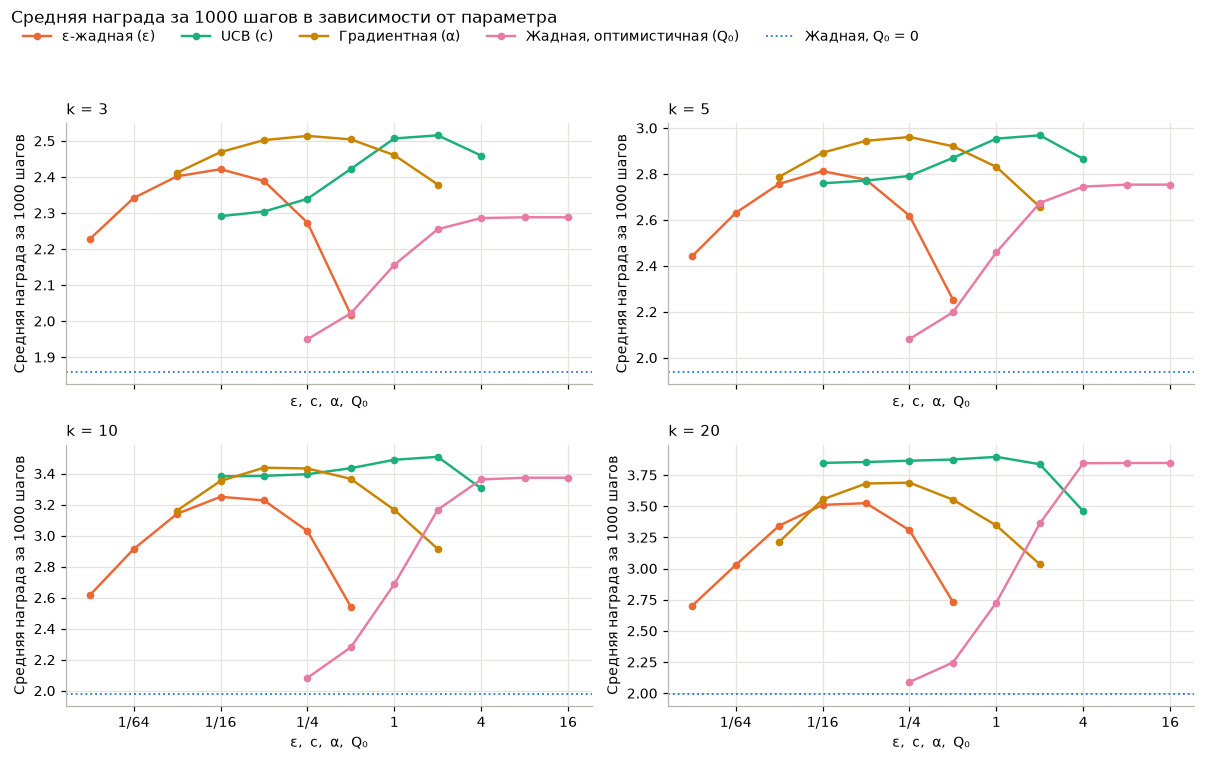

k =  3: ε-жадная — лучший ε = 0.0625 (2.421);  UCB — лучший c = 2 (2.516);  Градиентная — лучший α = 0.25 (2.514);  Жадная, оптимистичная — лучший Q₀ = 8 (2.288)
k =  5: ε-жадная — лучший ε = 0.0625 (2.812);  UCB — лучший c = 2 (2.968);  Градиентная — лучший α = 0.25 (2.961);  Жадная, оптимистичная — лучший Q₀ = 8 (2.754)
k = 10: ε-жадная — лучший ε = 0.0625 (3.251);  UCB — лучший c = 2 (3.508);  Градиентная — лучший α = 0.125 (3.438);  Жадная, оптимистичная — лучший Q₀ = 8 (3.374)
k = 20: ε-жадная — лучший ε = 0.125 (3.525);  UCB — лучший c = 1 (3.896);  Градиентная — лучший α = 0.25 (3.689);  Жадная, оптимистичная — лучший Q₀ = 8 (3.847)


In [9]:
# Для каждой стратегии: какие значения параметра пробуем, как создать агента, как подписать параметр.
# 2.0 ** np.arange(-7, 0) - это 1/128, 1/64, ..., 1/2
grid = {
    'ε-жадная': (2.0 ** np.arange(-7, 0), lambda p: partial(EpsilonGreedyAgent, epsilon=p), 'ε'),
    'UCB': (2.0 ** np.arange(-4, 3), lambda p: partial(UCBAgent, c=p), 'c'),
    'Градиентная': (2.0 ** np.arange(-5, 2), lambda p: partial(GradientAgent, alpha=p), 'α'),
    'Жадная, оптимистичная': (2.0 ** np.arange(-2, 5),
                              lambda p: partial(EpsilonGreedyAgent, epsilon=0.0, q0=p), 'Q₀'),
}
# study[k][стратегия] = список средних наград за 1000 шагов,
# по одному числу на каждое значение параметра
study = {k: {name: [run(random_env(k), make(p), N_STEPS, N_RUNS)['reward'].mean() for p in params]
             for name, (params, make, _) in grid.items()}
         for k in ARMS}

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for ax, k in zip(axes.flat, ARMS):
    for name, (params, _, pname) in grid.items():
        ax.plot(params, study[k][name], marker='o', markersize=4, color=COLORS[name],
                label=f'{name} ({pname})')
    # пунктир - обычная жадная стратегия, для сравнения
    greedy = comparison[k]['Жадная']['reward'].mean()
    ax.axhline(greedy, color=COLORS['Жадная'], linestyle=':', linewidth=1.2, label='Жадная, Q₀ = 0')
    ax.set_xscale('log', base=2)  # ось x - по степеням двойки
    # подписи оси: вместо 0.0625 пишем 1/16
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(
        lambda x, _: f'1/{int(round(1 / x))}' if x < 1 else f'{int(x)}'))
    ax.set_title(f'k = {k}', loc='left', fontsize=10)
    ax.set_xlabel('ε,  c,  α,  Q₀')
    ax.set_ylabel('Средняя награда за 1000 шагов')
fig.suptitle('Средняя награда за 1000 шагов в зависимости от параметра', x=0.01, ha='left')
top_legend(fig, axes[0, 0], ncol=5, top=0.92)
plt.show()

# для каждого k печатаем лучшее значение параметра у каждой стратегии
for k in ARMS:
    best = {name: (grid[name][0][int(np.argmax(v))], max(v)) for name, v in study[k].items()}
    print(f'k = {k:2d}: ' + ';  '.join(f'{name} — лучший {grid[name][2]} = {p:g} ({v:.3f})'
                                      for name, (p, v) in best.items()))

**Наблюдения.**

* У ε-жадной, UCB и градиентной стратегий зависимость от параметра — **перевёрнутая буква U**:
  мало исследования — агент застревает на плохой ручке, много — теряет награду на исследовании
  или учится нестабильно. У оптимистичной жадной стратегии кривая выходит на насыщение, когда Q₀ превышает
  максимально возможную ценность ручки (≈ 5).
* **Лучшие параметры почти не зависят от k:** ε ≈ 1/16 (1/8 при k = 20), c ≈ 2
  (1 при k = 20), α ≈ 1/8 … 1/4, Q₀ ≥ 4 … 8.
* **UCB лучшая при любом k** и меньше всех чувствительна к параметру: у неё самая широкая и плоская вершина.
  Общий порядок: UCB ≥ градиентная > ε-жадная.
* Оптимистичная жадная при k = 3 — худшая из настроенных (2.29), а при k = 20 — вторая (3.85, почти как UCB с 3.90).
  Перепробовать все ручки в начале стоит немного шагов, а ε-жадная при любом k тратит фиксированную долю
  шагов на случайные ходы. При малом k, наоборот, отсутствие исследования после начала обходится дорого:
  если агент ошибся между двумя-тремя близкими ручками, он эту ошибку уже не исправит.

## 8. Контрольная проверка на гауссовом стенде

Чтобы убедиться, что реализация верная, те же стратегии запущены на классическом 10-руком стенде Саттона и Барто
(q\*(a) ~ N(0, 1), награда ~ N(q\*(a), 1)). Там награды бывают отрицательными. Чтобы показать роль базовой линии
у градиентного метода, все награды сдвигаются на +4 (как в книге).

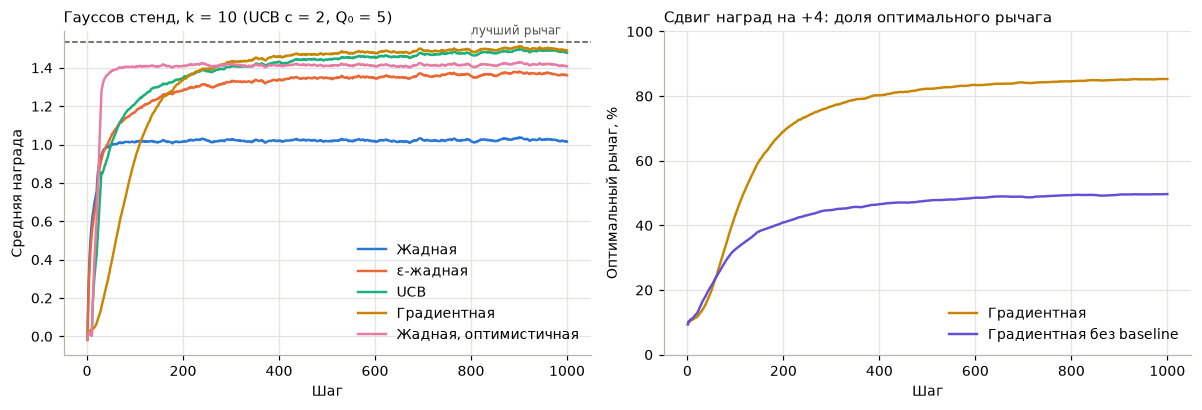

Жадная                           награда за 1000 шагов: 1.015   оптимальный рычаг (посл. 100): 35.0 %
ε-жадная                         награда за 1000 шагов: 1.306   оптимальный рычаг (посл. 100): 80.2 %
UCB                              награда за 1000 шагов: 1.387   оптимальный рычаг (посл. 100): 85.3 %
Градиентная                      награда за 1000 шагов: 1.349   оптимальный рычаг (посл. 100): 85.2 %
Жадная, оптимистичная            награда за 1000 шагов: 1.396   оптимальный рычаг (посл. 100): 69.5 %
Градиентная (+4)                 награда за 1000 шагов: 5.349   оптимальный рычаг (посл. 100): 85.2 %
Градиентная без baseline (+4)    награда за 1000 шагов: 5.091   оптимальный рычаг (посл. 100): 49.6 %


In [10]:
class ShiftedGaussianBanditEnv(GaussianBanditEnv):
    # Тот же гауссов стенд, но все ценности ручек сдвинуты на +4 (рис. 2.5 у Саттона и Барто).
    # Тогда почти все награды положительные - удобно проверить, зачем нужна базовая линия.

    def __init__(self, n_arms, n_runs, rng, shift=4.0):
        super().__init__(n_arms, n_runs, rng)  # создаём обычный стенд
        self.q_true += shift  # и сдвигаем все ценности
        self.best_value = self.q_true.max(axis=1)  # потолок тоже сдвинулся


# тот же набор стратегий, только без случайной, плюс оптимистичная жадная, и UCB с c = 2 как в книге
gauss_strategies = dict(strategies)
gauss_strategies.pop('Случайная')
gauss_strategies['Жадная, оптимистичная'] = partial(EpsilonGreedyAgent, epsilon=0.0, q0=5)
gauss_strategies['UCB'] = partial(UCBAgent, c=2.0)
gauss = {name: run(partial(GaussianBanditEnv, 10), make, N_STEPS, N_RUNS)
         for name, make in gauss_strategies.items()}
# градиентная с базовой линией и без - на сдвинутом стенде
shifted = {
    'Градиентная': run(partial(ShiftedGaussianBanditEnv, 10), partial(GradientAgent, alpha=0.1),
                       N_STEPS, N_RUNS),
    'Градиентная без baseline': run(partial(ShiftedGaussianBanditEnv, 10),
                                    partial(GradientAgent, alpha=0.1, baseline=False), N_STEPS, N_RUNS),
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
plot_curves(ax1, gauss, 'reward', COLORS, best=gauss['Жадная']['best_value'],
            title='Гауссов стенд, k = 10 (UCB c = 2, Q₀ = 5)')
ax1.legend(loc='lower right')
plot_curves(ax2, shifted, 'optimal', COLORS, title='Сдвиг наград на +4: доля оптимального рычага')
ax2.set_ylim(0, 100)
ax2.legend(loc='lower right')
plt.tight_layout()
plt.show()

for name, r in {**gauss, **{n + ' (+4)': r for n, r in shifted.items()}}.items():
    print(f"{name:32s} награда за 1000 шагов: {r['reward'].mean():.3f}   "
          f"оптимальный рычаг (посл. 100): {100 * r['optimal'][-100:].mean():.1f} %")

**Наблюдения.** На классическом стенде получаются те же закономерности, что у Саттона и Барто (рис. 2.2–2.5):
жадная стратегия выходит на ≈ 1.0, ε-жадная (ε = 0.1) — на ≈ 1.35, UCB (c = 2) и градиентная — выше.
Оптимистичная инициализация (Q₀ = 5) быстрее всех набирает награду в начале. При сдвиге наград на +4 градиентная
стратегия без базовой линии выбирает лучшую ручку лишь в ~50 % случаев, а с базовой линией — в 85 %.
Результаты совпадают с известными из книги, значит, реализация верная.

## 9. Сводная таблица

Средняя награда за 1000 шагов / % выбора лучшей ручки на последних 100 шагах. Параметры: ε = 0.1, c = 1, α = 0.1.

In [11]:
# Шапка таблицы: по колонке на каждое k
print(f"{'Стратегия':14s}" + ''.join(f'{f"k = {k}":>20s}' for k in ARMS))
print(f"{'':14s}" + ''.join(f'{"награда / опт. %":>20s}' for _ in ARMS))
for name in strategies:
    res = [comparison[k][name] for k in ARMS]  # результаты этой стратегии для каждого k
    row = [f"{r['reward'].mean():.3f} / {100 * r['optimal'][-100:].mean():4.1f}" for r in res]
    print(f'{name:14s}' + ''.join(f'{cell:>20s}' for cell in row))
# последняя строка - потолок, ценность лучшей ручки
ceiling = [comparison[k]['Жадная']['best_value'] for k in ARMS]
print(f"{'Потолок':14s}" + ''.join(f'{c:>13.3f}       ' for c in ceiling))

Стратегия                    k = 3               k = 5              k = 10              k = 20
                  награда / опт. %    награда / опт. %    награда / опт. %    награда / опт. %
Случайная             1.497 / 33.2        1.499 / 20.0        1.510 / 10.0        1.501 /  5.0
Жадная                1.858 / 49.2        1.937 / 31.7        1.980 / 17.0        1.995 /  9.1
ε-жадная              2.408 / 88.7        2.799 / 85.4        3.253 / 78.5        3.542 / 71.3
UCB                   2.507 / 91.9        2.954 / 88.2        3.489 / 80.5        3.896 / 79.1
Градиентная           2.494 / 95.4        2.933 / 92.9        3.422 / 83.6        3.662 / 65.8
Потолок               2.557               3.038               3.643               4.085       


## 10. Выводы

1. **Исследование необходимо.** Жадная стратегия с нулевыми начальными оценками почти не лучше случайной:
   она застревает на первой ручке, которая принесла выигрыш, и с ростом k её результат не растёт.
   На автомате из методички она даже хуже случайной.
2. **Лучшая стратегия в этих экспериментах — UCB** (c ≈ 1–2). У неё самая высокая средняя награда
   при всех k = 3 … 20, самое быстрое обучение и меньше всего зависимость от параметра.
   Исследует она не наугад, а прицельно: пробует те ручки, про которые меньше всего известно.
3. **Градиентный бандит** (softmax + стохастический градиентный подъём) с базовой линией и α ≈ 0.1–0.25
   по награде почти не уступает UCB, а при k ≤ 10 к концу обучения чаще всех выбирает лучшую ручку.
   Но он медленнее стартует и хуже справляется с большим числом ручек. Базовая линия заметно улучшает
   результат, особенно когда награды неотрицательные.
4. **ε-жадная стратегия** простая и надёжная, но из-за постоянной доли случайных ходов всегда теряет
   примерно ε × (q\*лучшей − средняя q\*). Лучшее ε ≈ 0.05–0.1. Маленькое ε учится слишком медленно,
   большое — быстро выходит на низкий уровень.
5. **Оптимистичная инициализация** — простой способ заставить жадного агента исследовать. Хорошо работает при большом
   числе ручек, если Q₀ не меньше максимальной ценности ручки. Но после начальной фазы агент больше не исследует.
6. **Зависимость от параметров** у всех методов показывает компромисс «исследование ↔ использование»: качество в
   зависимости от параметра исследования — перевёрнутая буква U, и лучшие значения мало зависят от числа ручек.
7. **С ростом числа ручек** исследование длится дольше, и все методы реже выбирают лучшую ручку.
   Методы с прицельным исследованием (UCB, оптимистичная инициализация) переносят это лучше, чем ε-жадный,
   который исследует наугад.

*Ограничения:* исследование проведено для стационарных бандитов (ценности ручек не меняются) на горизонте 1000 шагов.
Если бы ценности ручек менялись со временем, оценки пришлось бы обновлять с постоянным шагом, и выводы про UCB
и оптимистичную инициализацию могли бы измениться.